# 第7章：Titanicデータ分析を順に試す

2026年10月30日改訂の原稿に対応する学習用ノートブックです。
本文の分析手順に対応するPythonコード6本を順に収め、確認用セルと配布スクリプトを実行するセルを加えています。
AIの回答記録を新たに作ったものではありません。

## 目的

欠損値の確認、グループ別の可視化、分類モデルの評価を通じて、結果を自分で読む練習をします。
処理を選ぶ理由と結果の解釈は、書籍の第7章と合わせて確認してください。

## 準備

[Colabで開く](https://colab.research.google.com/github/yutakaJssst/ai-research-book/blob/main/downloads/chapter7/titanic-walkthrough.ipynb)から開き、先頭から順に実行してください。
実行にはGoogleアカウントへのログインが必要です。
必要なライブラリの準備と、データの取得をコードで行います。GPUは不要です。
編集した内容を残す場合は、Colabの「ファイル」から「ドライブにコピーを保存」を選びます。

データはKaggleの公開データセット [Titanic Dataset（Yasser H、版1）](https://www.kaggle.com/datasets/yasserh/titanic-dataset)から取得します。
配布元の表示はCC0: Public Domainです（2026年10月11日確認）。
元の[Titanicコンペティション](https://www.kaggle.com/c/titanic)の `train.csv` と、891行・12列の全値が一致することを確認しました。
ファイルの改行などによってSHA-256が異なる場合があるため、元データとの照合は読み込んだ値でも行いました。
データ本体は本サイトには置かず、実行時にKaggleから取得します。

取得できない場合は、Kaggleで利用条件を確認して取得した `train.csv` をColabのファイル一覧からアップロードしてください。
すでに `train.csv` があれば、そのファイルを使います。手元のJupyterでも同じ手順で実行できます。

### この教材の前提

訓練712件と評価179件へ分割し、補完値は訓練データだけから求めます。
`random_state=42`、`stratify=y` を指定します。
`Pclass` は簡略化のため数値として扱います。
この分析は関連を見る練習であり、生存の原因を特定するものではありません。

今回の保存済み数値は2026年10月15日に計算セルを上から順に再実行した結果です。
環境準備セルは既存環境が指定範囲を満たすことを確認し、ダウンロード画面のセルは実行していません。


## ライブラリを準備する

最初のセルで必要なライブラリを用意します。

In [ ]:
%pip install -q "pandas>=2,<4" "matplotlib>=3.8,<4" "numpy>=1.26,<3" "scikit-learn>=1.4,<2"

## データを取得する

版1のファイルを取得し、確認済みのSHA-256と照合してから保存します。

In [1]:
import hashlib
import io
import zipfile
from pathlib import Path
from urllib.request import urlopen

DATA_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "yasserh/titanic-dataset?datasetVersionNumber=1"
)
EXPECTED_SHA256 = "7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f"
data_path = Path("train.csv")

if not data_path.exists():
    with urlopen(DATA_URL, timeout=30) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as files:
        data = files.read("Titanic-Dataset.csv")
    if hashlib.sha256(data).hexdigest() != EXPECTED_SHA256:
        raise ValueError("確認済みのデータと異なります。配布元と実行手順を確認してください。")
    data_path.write_bytes(data)
    print("Kaggleの公開版1から train.csv を取得しました。")
else:
    print("既存の train.csv を使います。")


既存の train.csv を使います。


## 実行環境を記録する

ライブラリの版やデータが違うと結果も変わることがあります。まず版とデータの指紋（SHA-256）を記録します。

In [2]:
import sys
import hashlib
from pathlib import Path
import pandas as pd
import matplotlib
import sklearn

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("train.csv SHA-256:", hashlib.sha256(Path("train.csv").read_bytes()).hexdigest())

Python: 3.9.6
pandas: 2.3.2
matplotlib: 3.9.4
scikit-learn: 1.6.1
train.csv SHA-256: 7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f


## 手順

### 1. データの意味を確かめる

行数、列数、先頭の行、列の型、要約統計量を確認します。先頭行の個票を含むこのセルの保存済み出力は、再配布を避けるため掲載していません。自分の環境で実行して確認してください。

In [3]:
import pandas as pd

df = pd.read_csv("train.csv")

print(df.shape)      # 行数と列数
print(df.head())     # 先頭5行
df.info()            # 列ごとの型と欠損の有無
df.describe()        # 数値列の要約統計量

### 2. 欠損件数と割合を見る

件数だけで判断せず、欠損の理由や偏りを考えます。本文の処理方針は例であり、他のデータに一律には適用しません。

In [4]:
missing_count = df.isnull().sum()
missing_rate = (df.isnull().sum() / len(df) * 100).round(1)

pd.DataFrame({
    "missing_count": missing_count,
    "missing_rate(%)": missing_rate
})

### 3. 生存率と比較の基準を確かめる

生存を1、死亡を0としているため、平均値を生存率として読めます。全員を死亡と予測した場合の正解率も考えてください。

In [5]:
print(df["Survived"].value_counts())
print(df["Survived"].mean())

### 4. グループ別に可視化する

棒グラフの高さから関連を読みます。乗船港の差を、そのまま因果関係として解釈しないことが大切です。掲載用に整えた図は `gen_figures.py` で生成できます。

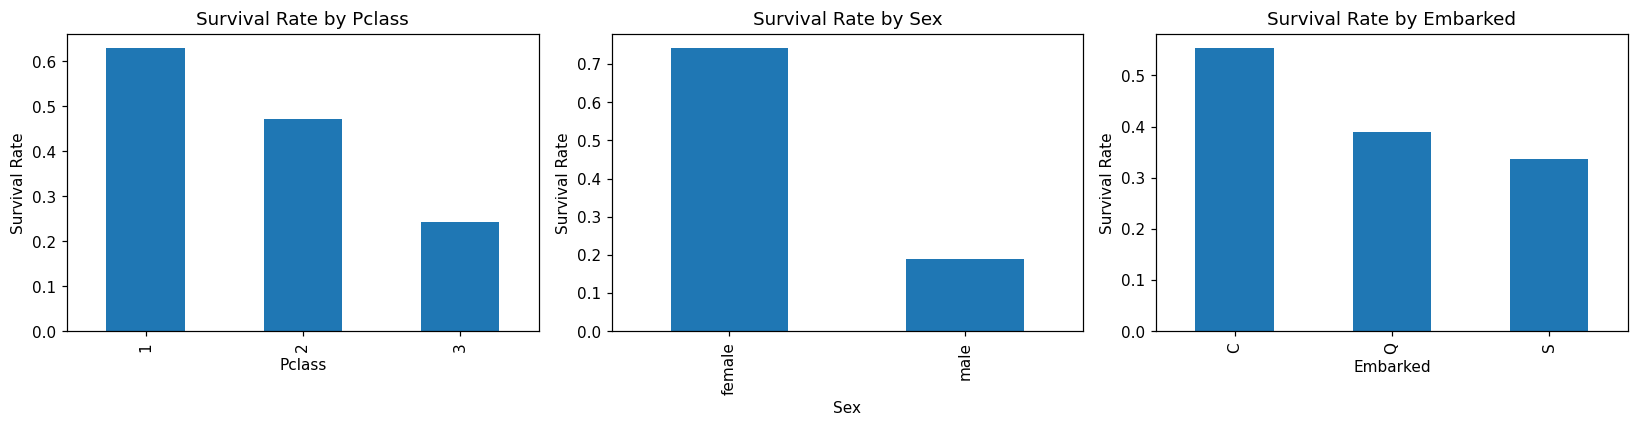

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["Pclass", "Sex", "Embarked"]):
    df.groupby(col)["Survived"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Survival Rate by {col}")
    ax.set_ylabel("Survival Rate")

plt.tight_layout()
plt.show()

### 5. 分割してから補完する

評価データの情報が補完値を通じて訓練に混ざらないよう、先に分割します。補完に使った値と説明変数の列を、後の確認セルでも点検します。
乗船港のカテゴリはC・Q・Sに固定し、訓練側と評価側で同じ符号化を使います。


In [7]:
from sklearn.model_selection import train_test_split

df_work = df.drop(
    columns=["PassengerId", "Name", "Ticket", "Cabin"])
df_work["Sex"] = df_work["Sex"].map({"male": 0, "female": 1})

X = df_work.drop("Survived", axis=1)
y = df_work["Survived"]

# 欠損値を埋める前に分割する
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 補完に使う値は訓練データだけから決める
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]
fill = {"Age": age_median, "Embarked": embarked_mode}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# 両方に同じカテゴリを指定し、Cを基準に符号化する
embarked_type = pd.CategoricalDtype(categories=["C", "Q", "S"])
X_train["Embarked"] = X_train["Embarked"].astype(embarked_type)
X_test["Embarked"] = X_test["Embarked"].astype(embarked_type)

# カテゴリ変数の数値化
X_train = pd.get_dummies(X_train, columns=["Embarked"],
                         drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=["Embarked"],
                        drop_first=True, dtype=int)


### 6. モデルを作り、評価する

ロジスティック回帰を使います。正解率だけでなく、混同行列でどちらの誤りが多いかを確かめます。

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))

0.8044692737430168
[[98 12]
 [23 46]]


## 確認

ここからは教材用に追加したセルです。件数、分割、本文の主要な結果を照合します。assertで止まったら数値を合わせるためにコードを変えず、データと実行環境を確認してください。

In [9]:
import numpy as np

assert df.shape == (891, 12)
assert df["PassengerId"].is_unique
assert int(df["Survived"].sum()) == 342
assert df[["Age", "Cabin", "Embarked"]].isnull().sum().tolist() == [177, 687, 2]
assert len(X_train) == 712 and len(X_test) == 179
assert X_train.index.intersection(X_test.index).empty
assert X_train.columns.tolist() == X_test.columns.tolist()
assert X_train.shape[1] == 8
assert not X_train.isnull().any().any()
assert not X_test.isnull().any().any()
assert age_median == df.loc[X_train.index, "Age"].median()
assert embarked_mode == df.loc[X_train.index, "Embarked"].mode()[0]

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
assert cm.sum() == len(y_test)
assert np.array_equal(cm, [[98, 12], [23, 46]])
assert round(accuracy_score(y_test, pred), 3) == 0.804
assert round(tp / (tp + fn), 3) == 0.667

print("照合を通過しました。")
print("生存率:", round(df["Survived"].mean() * 100, 1), "%")
print("全員死亡と予測した場合:", round((1 - df["Survived"].mean()) * 100, 1), "%")
print("補完値:", fill)
print("説明変数:", X_train.columns.tolist())
print("混同行列:", cm.tolist())
print("生存者の再現率:", round(tp / (tp + fn), 3))
print("係数:")
for name, value in zip(X_train.columns, model.coef_[0]):
    print(f"  {name}: {value:+.3f}")

照合を通過しました。
生存率: 38.4 %
全員死亡と予測した場合: 61.6 %
補完値: {'Age': 28.5, 'Embarked': 'S'}
説明変数: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
混同行列: [[98, 12], [23, 46]]
生存者の再現率: 0.667
係数:
  Pclass: -1.092
  Sex: +2.556
  Age: -0.039
  SibSp: -0.245
  Parch: -0.072
  Fare: +0.002
  Embarked_Q: +0.285
  Embarked_S: -0.383


## 自分の研究で使うとき

どちらの誤りが問題になるか、変数が予測の時点で手に入るかを考えてください。
同じ前処理をそのまま適用せず、欠損の意味や測定条件を確かめます。
AIが示した解釈を採用する際は、どの表や数値を根拠にしたかを記録します。

変更後は実行環境を再起動し、先頭から再実行して、古い変数や出力が残っていないか確認してください。


## 配布スクリプトで検算と図の生成を試す

ここまでの分析を確認したら、別途配布している `verify_titanic.py` と `gen_figures.py` も実行できます。
書籍に対応する2026年10月15日版のスクリプト（信頼区間はWilson法）を取得し、`titanic-scripts` フォルダで同じデータを使います。
数値検証と3枚の図の生成を終えると、図だけをまとめた `titanic-figures.zip` ができます。


In [10]:
import shutil
import subprocess
from zipfile import ZipFile

SCRIPT_BASE = (
    "https://raw.githubusercontent.com/yutakaJssst/ai-research-book/"
    "8ecaac8d29f6efe2485bff53f7c79008a21f7368/downloads/chapter7/"
)
scripts_dir = Path("titanic-scripts")
scripts_dir.mkdir(exist_ok=True)
for filename in ["verify_titanic.py", "gen_figures.py"]:
    with urlopen(SCRIPT_BASE + filename, timeout=30) as response:
        (scripts_dir / filename).write_bytes(response.read())
shutil.copyfile(data_path, scripts_dir / "train.csv")

for filename in ["verify_titanic.py", "gen_figures.py"]:
    result = subprocess.run(
        [sys.executable, str(scripts_dir / filename)],
        check=True, capture_output=True, text=True,
    )
    print(result.stdout)

with ZipFile("titanic-figures.zip", "w") as archive:
    for figure in sorted((scripts_dir / "figs").glob("*.pdf")):
        archive.write(figure, arcname=figure.name)
        print("生成した図:", figure.name)


=== Step 1: データの意味 ===
shape: (891, 12) (本文: (891, 12))

=== Step 2: 欠損値 ===
Age: 177件 (19.9%)
Cabin: 687件 (77.1%)
Embarked: 2件 (0.2%)
(本文: Age 177件19.9% / Cabin 687件77.1% / Embarked 2件0.2%)

=== Step 3: EDA ===
生存率: 38.4 % (本文: 38.4%)
全員死亡と予測した場合の正解率: 61.6 % (本文: 約62%)

=== 前処理後 ===
補完値: Age中央値 28.5 / Embarked最頻値 S
（全データの中央値は 28.0 。訓練データだけで決めるため一致しない）
説明変数の列数: 8 (本文: 8列)
列: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']

=== モデル ===
訓練: 712 評価: 179 (本文: 712 / 179)
正解率: 0.804 (本文: 0.804)
混同行列:
 [[98 12]
 [23 46]] 
(本文: TN98 FP12 / FN23 TP46)
生存者の再現率: 0.667 (本文: 0.667)

=== 係数 ===
Pclass: -1.092
Sex: +2.556
Age: -0.039
SibSp: -0.245
Parch: -0.072
Fare: +0.002
Embarked_Q: +0.285
Embarked_S: -0.383
(本文: Sex +2.558 / Pclass -1.093 / Fare +0.002)

survival rates by Pclass: {1: 0.63, 2: 0.473, 3: 0.242}
survival rates by Sex: {'female': 0.742, 'male': 0.189}
survival rates by Embarked: {'C': 0.554, 'Q': 0.39, 'S': 0.337}
Fare mean/median: 32.2 14.5
Fare > 300:

### 図をパソコンへ保存する

図を保存したいときだけ、次のセルを実行します。
ColabではZIPのダウンロードが始まります。Jupyterではダウンロードリンクを表示します。


In [ ]:
try:
    from google.colab import files
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink("titanic-figures.zip"))
else:
    files.download("titanic-figures.zip")
